In [1]:
!pip install sympy==1.10.1

In [2]:
import sympy as sp
import matplotlib.pyplot as plt
import numpy as np
from sympy.utilities.lambdify import lambdify

In [3]:
plt.rc('font', size=15);
plt.rc('figure', figsize=(16,9));

# LP 1.1

In [4]:
x = sp.symbols('x');
f = (x**2 + x)*sp.exp(x);

df = sp.Derivative(f, (x,17))
y = df.doit()
sy = sp.simplify(y)

sy

(x**2 + 35*x + 289)*exp(x)

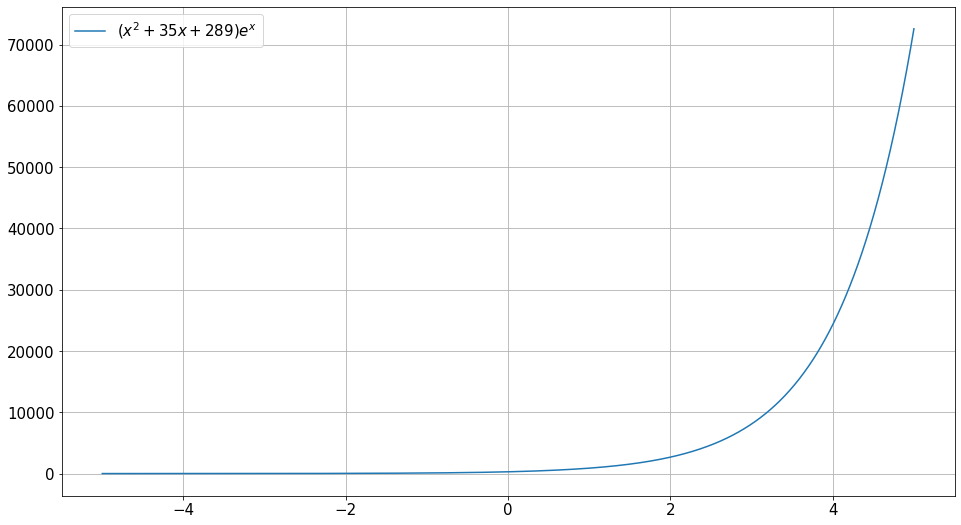

In [5]:
xs = np.linspace(-5, 5, 1000);


yy = np.vectorize(lambdify(x, sy));
plt.plot(xs, yy(xs), label = "$%s$"%sp.latex(sy))
plt.legend()
plt.grid()

# LP 1.2

In [6]:
t=sp.symbols('t')
x=sp.Function('x')
eq1=sp.Eq(
    sp.Derivative(x(t), t), 
    sp.exp(2*t-x(t))
)

eq2=sp.Eq(
    sp.Derivative(x(t), t), 
    -sp.sqrt(3)*t**2 + 2*x(t)
)

eq3=sp.Eq(
    sp.Derivative(x(t), t), 
    (t/20 + x(t))/(x(t)-t)
)


f1=sp.dsolve(eq1, ics={x(1):2})
f1_s=f1.rhs
f2=sp.dsolve(eq2, ics={x(1):2})
f2_s=f2.rhs

f3=sp.dsolve(eq3)

f31 = f3[0];
f32 = f3[1];

C1 = sp.symbols("C1");

eqn31=sp.Eq(
    2,
    f31.rhs
)
C=sp.solve(eqn31, C1)[0].subs(t,1);
f31 = f31.rhs.subs(C1,C);
f31.subs(t,1) == 2 #False

eqn32=sp.Eq(
    2,
    f32.rhs
)
C=sp.solve(eqn32, C1)[0].subs(t,1);
f32 = f32.rhs.subs(C1,C);
f32.subs(t,1) == 2 #True


True

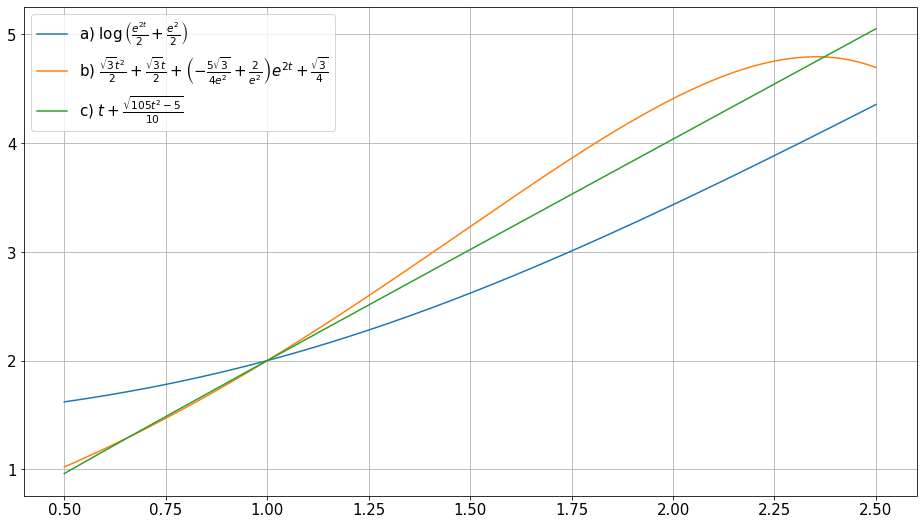

In [18]:
ts = np.linspace(0.5, 2.5, 1000);

ff1 = np.vectorize(lambdify(t, f1_s));
ff2 = np.vectorize(lambdify(t, f2_s));
ff32 = np.vectorize(lambdify(t, f32));

plt.plot(ts, ff1(ts), label = "a) " + "$%s$"%sp.latex(f1_s))
plt.plot(ts, ff2(ts), label = "b) " + "$%s$"%sp.latex(f2_s))
plt.plot(ts, ff32(ts), label = "c) " + "$%s$"%sp.latex(f32))

plt.legend()
plt.grid()